# Representation vs planning: do probes, RankMe or LiDAR predict success?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/comparisons/representation_vs_planning.ipynb)

Self-supervised encoders are usually compared by what a probe reads from their features, or by label-free scores of the features themselves: [RankMe](https://arxiv.org/abs/2210.02885), the effective rank of the embeddings, and [LiDAR](https://arxiv.org/abs/2312.04000), the effective rank of their linear discriminant matrix. A world model is used for something else: planning. This notebook trains the five models of the [main benchmark](main_benchmark.ipynb) with the same recipes, plus three cheap JEPAs from the library ([LpWM](../action/lpwm.ipynb), [Variational JEPA](../action/varjepa.ipynb), [Flow-JEPA](../action/flowjepa.ipynb)), measures each representation on held-out frames, then plans with the main benchmark's protocol and asks whether any of the measures ranks the models the way planning success does.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]" timm einops

In [2]:
import itertools
import time

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import DINOWM, PLDM, TDMPC2, FlowJEPA, LeWM, LpWM, PLDMEncoder, RoboJEPA, VariationalJEPA
from torch_world.models.tdmpc import pixel_encoder
from torch_world.nn import CLSEncoder, PatchTokens, VideoTokens
from torch_world.planning import CEM, MPPI
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data
The main benchmark's dataset: a point wanders through two rooms joined by a door, keeping its previous action 80% of the time, 1024 episodes of 65 steps. A second set of 512 episodes of 17 steps, from another seed, is held out for the representation measures.

In [3]:
data = TwoRooms(batch_size=1024, device=device).collect(65, generator=torch.Generator().manual_seed(0))
held_out = TwoRooms(batch_size=512, device=device).collect(17, generator=torch.Generator().manual_seed(2))


def loader(window):
    return DataLoader(TrajectoryDataset(data, window=window), batch_size=128, shuffle=True, drop_last=True)

## Models
The main benchmark's five models, built in the same order from the same seed, then three JEPAs with LeWM's encoder and predictor size: LpWM's sparse non-negative codes, Variational JEPA's Gaussian predictor with an EMA target, and Flow-JEPA's flow-matching predictor, which samples the 8 future embeddings of a plan jointly (`num_preds=8`, the planning horizon). All act on every frame (no frameskip), so one planner fits all the CEM models.

In [4]:
predictor = dict(depth=4, num_heads=4, head_dim=32, mlp_dim=512)
models = {
    "LeWM": LeWM(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, embed_dim=128, proj_dim=512, lamb=0.05, **predictor),
    "PLDM": PLDM(PLDMEncoder(img_size=64, latent_dim=128), action_dim=2, latent_dim=128),
    "DINO-WM": DINOWM(PatchTokens.from_hub("dinov2_vits14", size=56), num_patches=16, embed_dim=384, action_dim=2, **predictor),
    "V-JEPA 2-AC": RoboJEPA(embed_dim=768, action_dim=2, encoder=VideoTokens.from_hub("vjepa2_1_vit_base_384", size=64), predictor_dim=256, depth=4, num_heads=4),
    "TD-MPC2": TDMPC2(pixel_encoder(in_channels=6), action_dim=2, latent_dim=512, mlp_dim=512, discount=TDMPC2.episode_discount(60)),
}
small = dict(embed_dim=128, proj_dim=512, **predictor)
models.update({
    "LpWM": LpWM(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, **small),
    "Variational JEPA": VariationalJEPA(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, **small),
    "Flow-JEPA": FlowJEPA(CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4), action_dim=2, num_preds=8, **small),
})
for name, model in models.items():
    print(f"{name:17s} {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:5.2f}M trainable parameters")

/clusterhome/kleyton/pytorch-world-p2-20261025/pydeps/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


LeWM               2.34M trainable parameters
PLDM               0.54M trainable parameters
DINO-WM            2.45M trainable parameters
V-JEPA 2-AC        3.56M trainable parameters
TD-MPC2            4.86M trainable parameters
LpWM               2.34M trainable parameters
Variational JEPA   2.42M trainable parameters
Flow-JEPA          2.37M trainable parameters


TD-MPC2 learns from rewards, so it gets goals by hindsight, as in the main benchmark: its input is the frame and the goal image stacked on channels.

In [5]:
def hindsight(batch):
    pixels, states = batch["pixels"], batch["states"]  # (B, 8, ...)
    B = len(pixels)
    same = torch.rand(B, device=device) < 0.5
    other = torch.where(same, torch.arange(B, device=device), torch.randperm(B, device=device))
    goal_pixels, goal_states = pixels[other, -1], states[other, -1]
    obs = torch.cat([pixels[:, :4], goal_pixels[:, None].expand(-1, 4, -1, -1, -1)], dim=2)
    rewards = -(states[:, 1:4] - goal_states[:, None]).norm(dim=-1)
    return obs, batch["actions"][:, :3], rewards

## Train
Five epochs each with the main benchmark's recipes; the three JEPAs use the learning rate and clipping of their own notebooks.

LeWM                2.6 min


PLDM                8.1 min


DINO-WM             2.8 min


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2-AC        10.3 min


TD-MPC2             1.0 min


LpWM                2.8 min


Variational JEPA    3.1 min


Flow-JEPA           5.1 min


/clusterhome/kleyton/pytorch-world/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


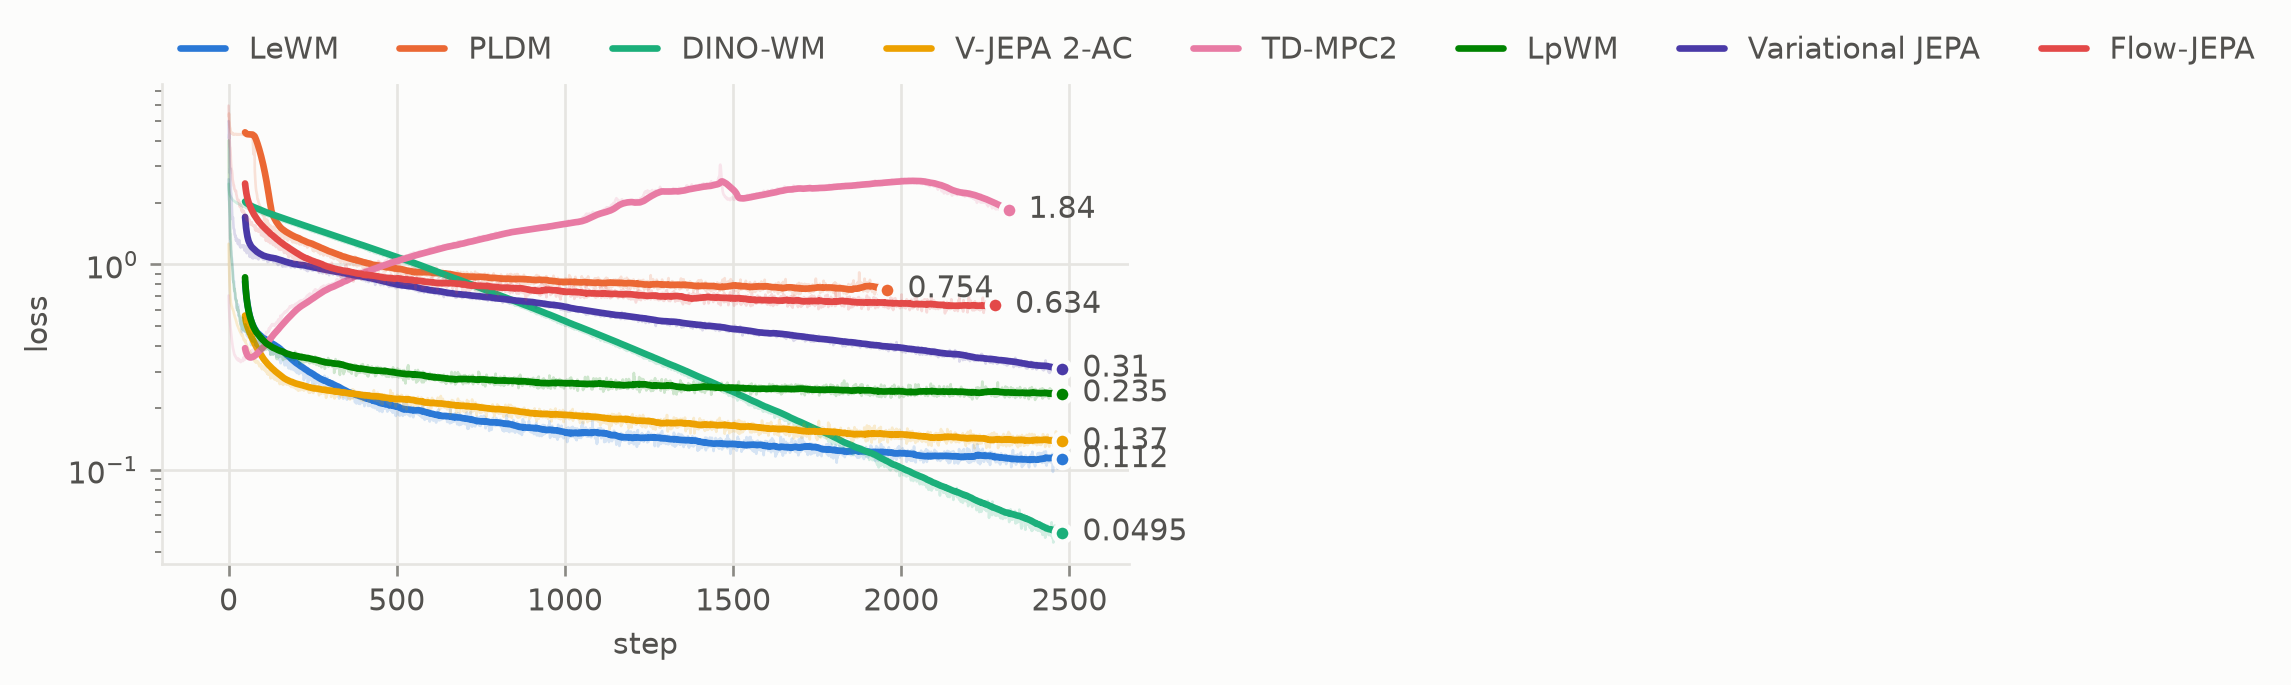

In [6]:
v_jepa = models["V-JEPA 2-AC"]
tdmpc2 = models["TD-MPC2"]
var_jepa = models["Variational JEPA"]
recipes = {
    "LeWM": dict(window=4),
    "PLDM": dict(window=17, lr=1e-3, weight_decay=0),
    "DINO-WM": dict(window=4),
    "V-JEPA 2-AC": dict(window=4, inputs=lambda b: (v_jepa.encode(b["pixels"]), b["actions"])),
    "TD-MPC2": dict(window=8, inputs=hindsight, lr=3e-4, clip=20, step=tdmpc2.update_target),
    "LpWM": dict(window=4, lr=3e-4, clip=1.0),
    "Variational JEPA": dict(window=4, lr=3e-4, step=lambda: var_jepa.update_target(0.99)),
    "Flow-JEPA": dict(window=9, lr=3e-4, clip=1.0),
}
logs, minutes = {}, {}
for name, model in models.items():
    recipe = dict(recipes[name])
    tic = time.time()
    logs[name] = fit(model.to(device), loader(recipe.pop("window")), epochs=5, **recipe)["loss"]
    minutes[name] = (time.time() - tic) / 60
    print(f"{name:17s} {minutes[name]:5.1f} min")
plots.curves({name: log for name, log in logs.items() if min(log) > 0}, smooth=50)  # a Gaussian NLL can go below 0

## Representation
Every measure is taken on the latent the planner compares, flattened: one embedding for LeWM, PLDM, TD-MPC2 and the three JEPAs, 16 patch tokens for DINO-WM and V-JEPA 2-AC. TD-MPC2 never encodes a frame alone, so each held-out episode is paired with the last frame of another episode as its goal image.

In [7]:
@torch.no_grad()
def encode(name, frames, goals=None):
    # Latents (N, ...) of frames (N, 3, H, W); TD-MPC2 sees each frame stacked with its goal image.
    out = []
    for i in range(0, len(frames), 256):
        x = frames[i : i + 256, None]
        if name == "TD-MPC2":
            x = torch.cat([x, goals[i : i + 256, None]], dim=2)
        out.append(models[name].encode(x)[:, 0].float())
    return torch.cat(out)


E, T = held_out["states"].shape[:2]
goal_of_episode = held_out["pixels"][torch.randperm(E, generator=torch.Generator().manual_seed(3)), -1]
frame_goals = goal_of_episode.repeat_interleave(T, 0)
latents = {name: encode(name, held_out["pixels"].flatten(0, 1), frame_goals).unflatten(0, (E, T)) for name in models}
for name, z in latents.items():
    print(f"{name:17s} latent {tuple(z.shape[2:])}")

/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


LeWM              latent (128,)
PLDM              latent (128,)
DINO-WM           latent (16, 384)
V-JEPA 2-AC       latent (1, 4, 4, 768)
TD-MPC2           latent (512,)
LpWM              latent (128,)
Variational JEPA  latent (128,)
Flow-JEPA         latent (128,)


**Probes.** The first 256 held-out episodes train each probe and the other 256 test it, so no test frame has a near-duplicate in training. A ridge regression reads the position (R²); a logistic regression and a 20-nearest-neighbor vote read the room. The room is a coarse property, so an attentive probe ([V-JEPA](https://arxiv.org/abs/2404.08471)'s, one learned query over the tokens, or over the single embedding) also classifies the position into an 8×8 grid of cells, a finer non-linear read-out. **RankMe** is the effective rank of the test latents, centered first because the frames share a mostly empty floor.

In [8]:
states = held_out["states"]
position, room = states, (states[..., 0] > 0.5).long()  # room 1 is right of the wall
cell = (states.clamp(0, 1 - 1e-6) * 8).long()
cell = cell[..., 1] * 8 + cell[..., 0]
train, test = slice(None, E // 2), slice(E // 2, None)

table = {}
for name, z in latents.items():
    tokens = z.flatten(2, -2) if z.dim() > 3 else z[:, :, None]  # (E, T, tokens, D)
    x, tok = z.flatten(2), tokens
    row = table.setdefault(name, {})
    tic = time.time()
    row["position R²"] = metrics.linear_probe(x[train].flatten(0, 1), position[train].flatten(0, 1), x[test].flatten(0, 1), position[test].flatten(0, 1)).score
    row["room, linear"] = metrics.linear_probe(x[train].flatten(0, 1), room[train].flatten(), x[test].flatten(0, 1), room[test].flatten()).score
    row["room, kNN"] = metrics.knn_accuracy(x[train].flatten(0, 1), room[train].flatten(), x[test].flatten(0, 1), room[test].flatten(), center=True).score
    row["cell, attentive"] = metrics.attentive_probe(tok[train].flatten(0, 1), cell[train].flatten(), tok[test].flatten(0, 1), cell[test].flatten(), generator=torch.Generator().manual_seed(0)).score
    row["RankMe"] = metrics.rankme(x[test].flatten(0, 1), center=True)
    print(f"{name:17s} " + "  ".join(f"{k} {v:.3g}" for k, v in row.items()) + f"   ({time.time() - tic:.0f} s)")

LeWM              position R² 0.998  room, linear 0.997  room, kNN 0.996  cell, attentive 0.966  RankMe 41.6   (2 s)


PLDM              position R² 1  room, linear 0.998  room, kNN 0.996  cell, attentive 0.965  RankMe 42.8   (1 s)


DINO-WM           position R² 1  room, linear 1  room, kNN 0.997  cell, attentive 0.954  RankMe 265   (76 s)


V-JEPA 2-AC       position R² 1  room, linear 1  room, kNN 0.997  cell, attentive 0.952  RankMe 589   (78 s)


TD-MPC2           position R² -21.5  room, linear 0.946  room, kNN 0.839  cell, attentive 0.654  RankMe 234   (2 s)


LpWM              position R² 0.99  room, linear 1  room, kNN 0.997  cell, attentive 0.965  RankMe 82.4   (2 s)


Variational JEPA  position R² 0.978  room, linear 1  room, kNN 0.998  cell, attentive 0.974  RankMe 78.9   (1 s)


Flow-JEPA         position R² 0.997  room, linear 0.996  room, kNN 0.996  cell, attentive 0.948  RankMe 17.6   (1 s)


**LiDAR** needs surrogate classes, each seen through several views. A class here is one of 1000 free states, and its 16 views are nearby states, the point moved by Gaussian noise of 0.02 (a fifth of a step, kept out of the wall), all rendered. A representation scores high when it separates different states much more than it spreads one state's small moves.

In [9]:
env = TwoRooms(device=device)
g = torch.Generator().manual_seed(4)
centers = env.free(1000, generator=g)
views = (centers[:, None] + 0.02 * torch.randn(1000, 16, 2, generator=g).to(device)).clamp(env.low, env.high)
views = torch.where(env.blocked(views)[..., None], centers[:, None].expand_as(views), views)
view_pixels = env.render(views.flatten(0, 1))
view_goals = held_out["pixels"].flatten(0, 1)[torch.randint(E * T, (1000,), generator=g)].repeat_interleave(16, 0)
for name in models:
    z = encode(name, view_pixels, view_goals).flatten(1).unflatten(0, (1000, 16))
    table[name]["LiDAR"] = metrics.lidar(z)
    print(f"{name:17s} LiDAR {table[name]['LiDAR']:.1f}")

LeWM              LiDAR 17.3


PLDM              LiDAR 13.1


DINO-WM           LiDAR 28.8


V-JEPA 2-AC       LiDAR 37.5


TD-MPC2           LiDAR 103.5


LpWM              LiDAR 28.7


Variational JEPA  LiDAR 25.1


Flow-JEPA         LiDAR 9.3


## Prediction
From the first frame of 9-frame held-out windows, each model rolls its latent forward under the recorded actions, as a planner does (Flow-JEPA draws one sample). The error at each step is the squared distance to the encoded frame, divided by the total variance of the latents, so 1 is as far as predicting the mean latent and the scale of each latent space cancels.

LeWM              1 step 0.011   8 steps 0.065


PLDM              1 step 0.156   8 steps 0.202


DINO-WM           1 step 0.137   8 steps 0.406


V-JEPA 2-AC       1 step 0.220   8 steps 0.989
TD-MPC2           1 step 0.505   8 steps 0.731


LpWM              1 step 0.030   8 steps 0.140


Variational JEPA  1 step 0.086   8 steps 0.307


Flow-JEPA         1 step 0.245   8 steps 0.407


/clusterhome/kleyton/pytorch-world/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


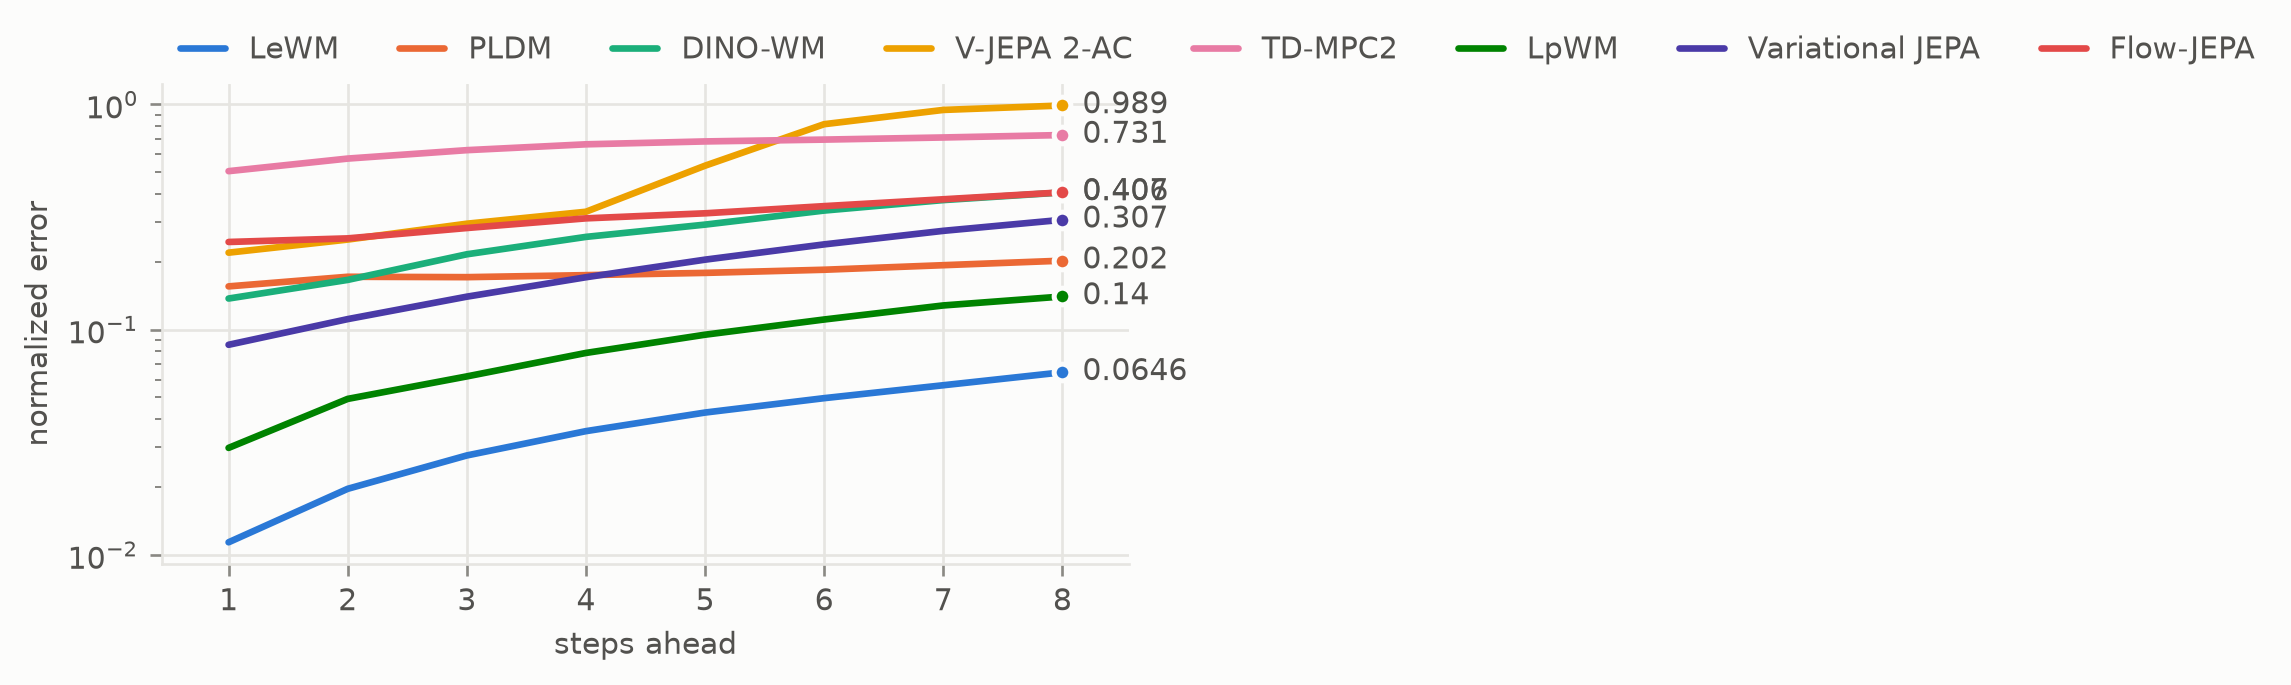

In [10]:
windows = {key: torch.cat([held_out[key][:, :9], held_out[key][:, 8:]]) for key in ("pixels", "actions")}
window_goals = torch.cat([goal_of_episode, goal_of_episode])
torch.manual_seed(0)
errors = {}
for name, model in models.items():
    W = len(windows["pixels"])
    z = encode(name, windows["pixels"].flatten(0, 1), window_goals.repeat_interleave(9, 0)).unflatten(0, (W, 9))
    with torch.no_grad():
        pred = torch.cat([model.rollout(z[i : i + 128, :1], windows["actions"][i : i + 128, :8]).float() for i in range(0, W, 128)])
    flat = latents[name].flatten(0, 1).flatten(1)
    variance = (flat - flat.mean(0)).square().sum(1).mean()
    errors[name] = ((pred - z).flatten(2).square().sum(-1).mean(0) / variance)[1:].tolist()
    table[name]["1-step error"], table[name]["8-step error"] = errors[name][0], errors[name][-1]
    print(f"{name:17s} 1 step {errors[name][0]:.3f}   8 steps {errors[name][-1]:.3f}")
plots.curves({name: (range(1, 9), e) for name, e in errors.items()}, smooth=1, xlabel="steps ahead", ylabel="normalized error")

**Distance fidelity.** A planner only needs the latent distance to the goal to fall as the agent gets closer along a feasible path. For 2000 random pairs of free states, this is the rank correlation (Spearman) between the model's own planning cost from one to the other and their geodesic distance, the shortest path through the door. TD-MPC2's MPPI plans with its value function rather than a latent distance; its number uses the squared distance between the latents of the start and of the goal, both paired with the goal image.

In [11]:
def ranks(x):
    # Ranks of the values in x (N,), from 0, with ties sharing their average rank.
    x = torch.as_tensor(x, dtype=torch.float64)
    return (x[:, None] > x[None]).sum(1) + ((x[:, None] == x[None]).sum(1) - 1) / 2


def spearman(x, y):
    return torch.corrcoef(torch.stack([ranks(x), ranks(y)]))[0, 1].item()


def kendall(x, y):  # tau-b
    x, y = torch.as_tensor(x, dtype=torch.float64), torch.as_tensor(y, dtype=torch.float64)
    sx, sy = (x[:, None] - x[None]).sign(), (y[:, None] - y[None]).sign()
    return ((sx * sy).sum() / (sx.abs().sum() * sy.abs().sum()).sqrt()).item()


def geodesic(s, g):
    door = torch.stack([torch.full((33,), 0.5), torch.linspace(0.42, 0.58, 33)], -1).to(s)  # where the point fits
    through = ((s[:, None] - door).norm(dim=-1) + (door - g[:, None]).norm(dim=-1)).min(1).values
    return torch.where(env.room(s) == env.room(g), (s - g).norm(dim=-1), through)


g = torch.Generator().manual_seed(5)
starts, goals = env.free(2000, generator=g), env.free(2000, generator=g)
start_pixels, goal_pixels = env.render(starts), env.render(goals)
for name, model in models.items():
    z_start, z_goal = encode(name, start_pixels, goal_pixels), encode(name, goal_pixels, goal_pixels)
    with torch.no_grad():
        cost = (z_start - z_goal).square().flatten(1).sum(1) if name == "TD-MPC2" else model.cost(z_start[:, None], z_goal)
    table[name]["distance fidelity"] = spearman(cost.cpu(), geodesic(starts, goals).cpu())
    print(f"{name:17s} ρ(cost, geodesic distance) = {table[name]['distance fidelity']:.3f}")

LeWM              ρ(cost, geodesic distance) = 0.393
PLDM              ρ(cost, geodesic distance) = 0.714


DINO-WM           ρ(cost, geodesic distance) = 0.327


/clusterhome/kleyton/.local/share/uv/python/cpython-3.12.13-linux-aarch64-gnu/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


V-JEPA 2-AC       ρ(cost, geodesic distance) = 0.255
TD-MPC2           ρ(cost, geodesic distance) = -0.075
LpWM              ρ(cost, geodesic distance) = 0.510


Variational JEPA  ρ(cost, geodesic distance) = 0.205
Flow-JEPA         ρ(cost, geodesic distance) = 0.539


## Plan
The main benchmark's protocol: 32 tasks with the goal in the same room and 32 in the other room, 60 steps, success when the point comes within 0.1 of the goal at any step, 95% Wilson intervals. The CEM models share one planner; TD-MPC2 plans with MPPI and its value function.

In [12]:
cem = CEM(horizon=8, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
mppi = MPPI(horizon=3, action_dim=2, num_samples=256, num_elites=32, num_pi_trajs=12, iterations=4)
env = TwoRooms(batch_size=32, device=device)


def policies(goal_images):
    out = {name: evaluation.goal_policy(model, cem, goal_images) for name, model in models.items() if name != "TD-MPC2"}
    mppi.reset()
    out["TD-MPC2"] = lambda obs: mppi(tdmpc2, tdmpc2.encode(torch.cat([obs, goal_images], dim=1)[:, None]))[:, 0]
    out["random actions"] = evaluation.random_policy(env)
    return out


results = {}
for task, same_room in [("same room", True), ("other room", False)]:
    start, goal = env.tasks(torch.Generator().manual_seed(1), same_room=same_room)
    results[task] = evaluation.goal_reaching(env, policies(env.render(goal)), start, goal, steps=60, success="reached")
    print(f"== {task}\n{results[task]}")

== same room
                            success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM                 72% [55%, 84%]      72%       2          0.0256      0.87   0.149       0.369        442
PLDM               100% [89%, 100%]     100%    2.78          0.0245     0.935   0.298        0.28       9.94
DINO-WM              91% [76%, 97%]      91%    2.66          0.0422     0.806   0.183       0.441    7.3e+03
V-JEPA 2-AC          91% [76%, 97%]      91%    2.93          0.0242     0.915   0.303       0.325   2.22e+04
LpWM                 88% [72%, 95%]      88%    2.46          0.0248     0.907   0.183       0.415        447
Variational JEPA     75% [58%, 87%]      75%    2.42          0.0195     0.899   0.184       0.365        447
Flow-JEPA          100% [89%, 100%]     100%    3.28          0.0276     0.901    0.18       0.493   1.75e+03
TD-MPC2              44% [28%, 61%]      50%       4           0.246  -0.00348     0.1       0.622       6.

== other room
                            success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LeWM                 28% [16%, 45%]      28%    4.33           0.539   -0.0346   0.114       0.317        442
PLDM                 88% [72%, 95%]      88%    6.57          0.0256     0.962    0.38       0.347       9.91
DINO-WM              25% [13%, 42%]      25%    4.38           0.518      0.16  0.0884       0.429   7.28e+03
V-JEPA 2-AC          31% [18%, 49%]      31%     8.5           0.394     0.312   0.126       0.431   2.22e+04
LpWM                 25% [13%, 42%]      25%     4.5           0.606  0.000117  0.0838       0.341        446
Variational JEPA     25% [13%, 42%]      25%     6.5           0.619   -0.0373  0.0832       0.327        447
Flow-JEPA            38% [23%, 55%]      38%    9.25           0.323     0.237   0.105       0.493   1.75e+03
TD-MPC2               19% [9%, 35%]      19%    18.3           0.466     0.295  0.0482       0.601       5

/clusterhome/kleyton/pytorch-world/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


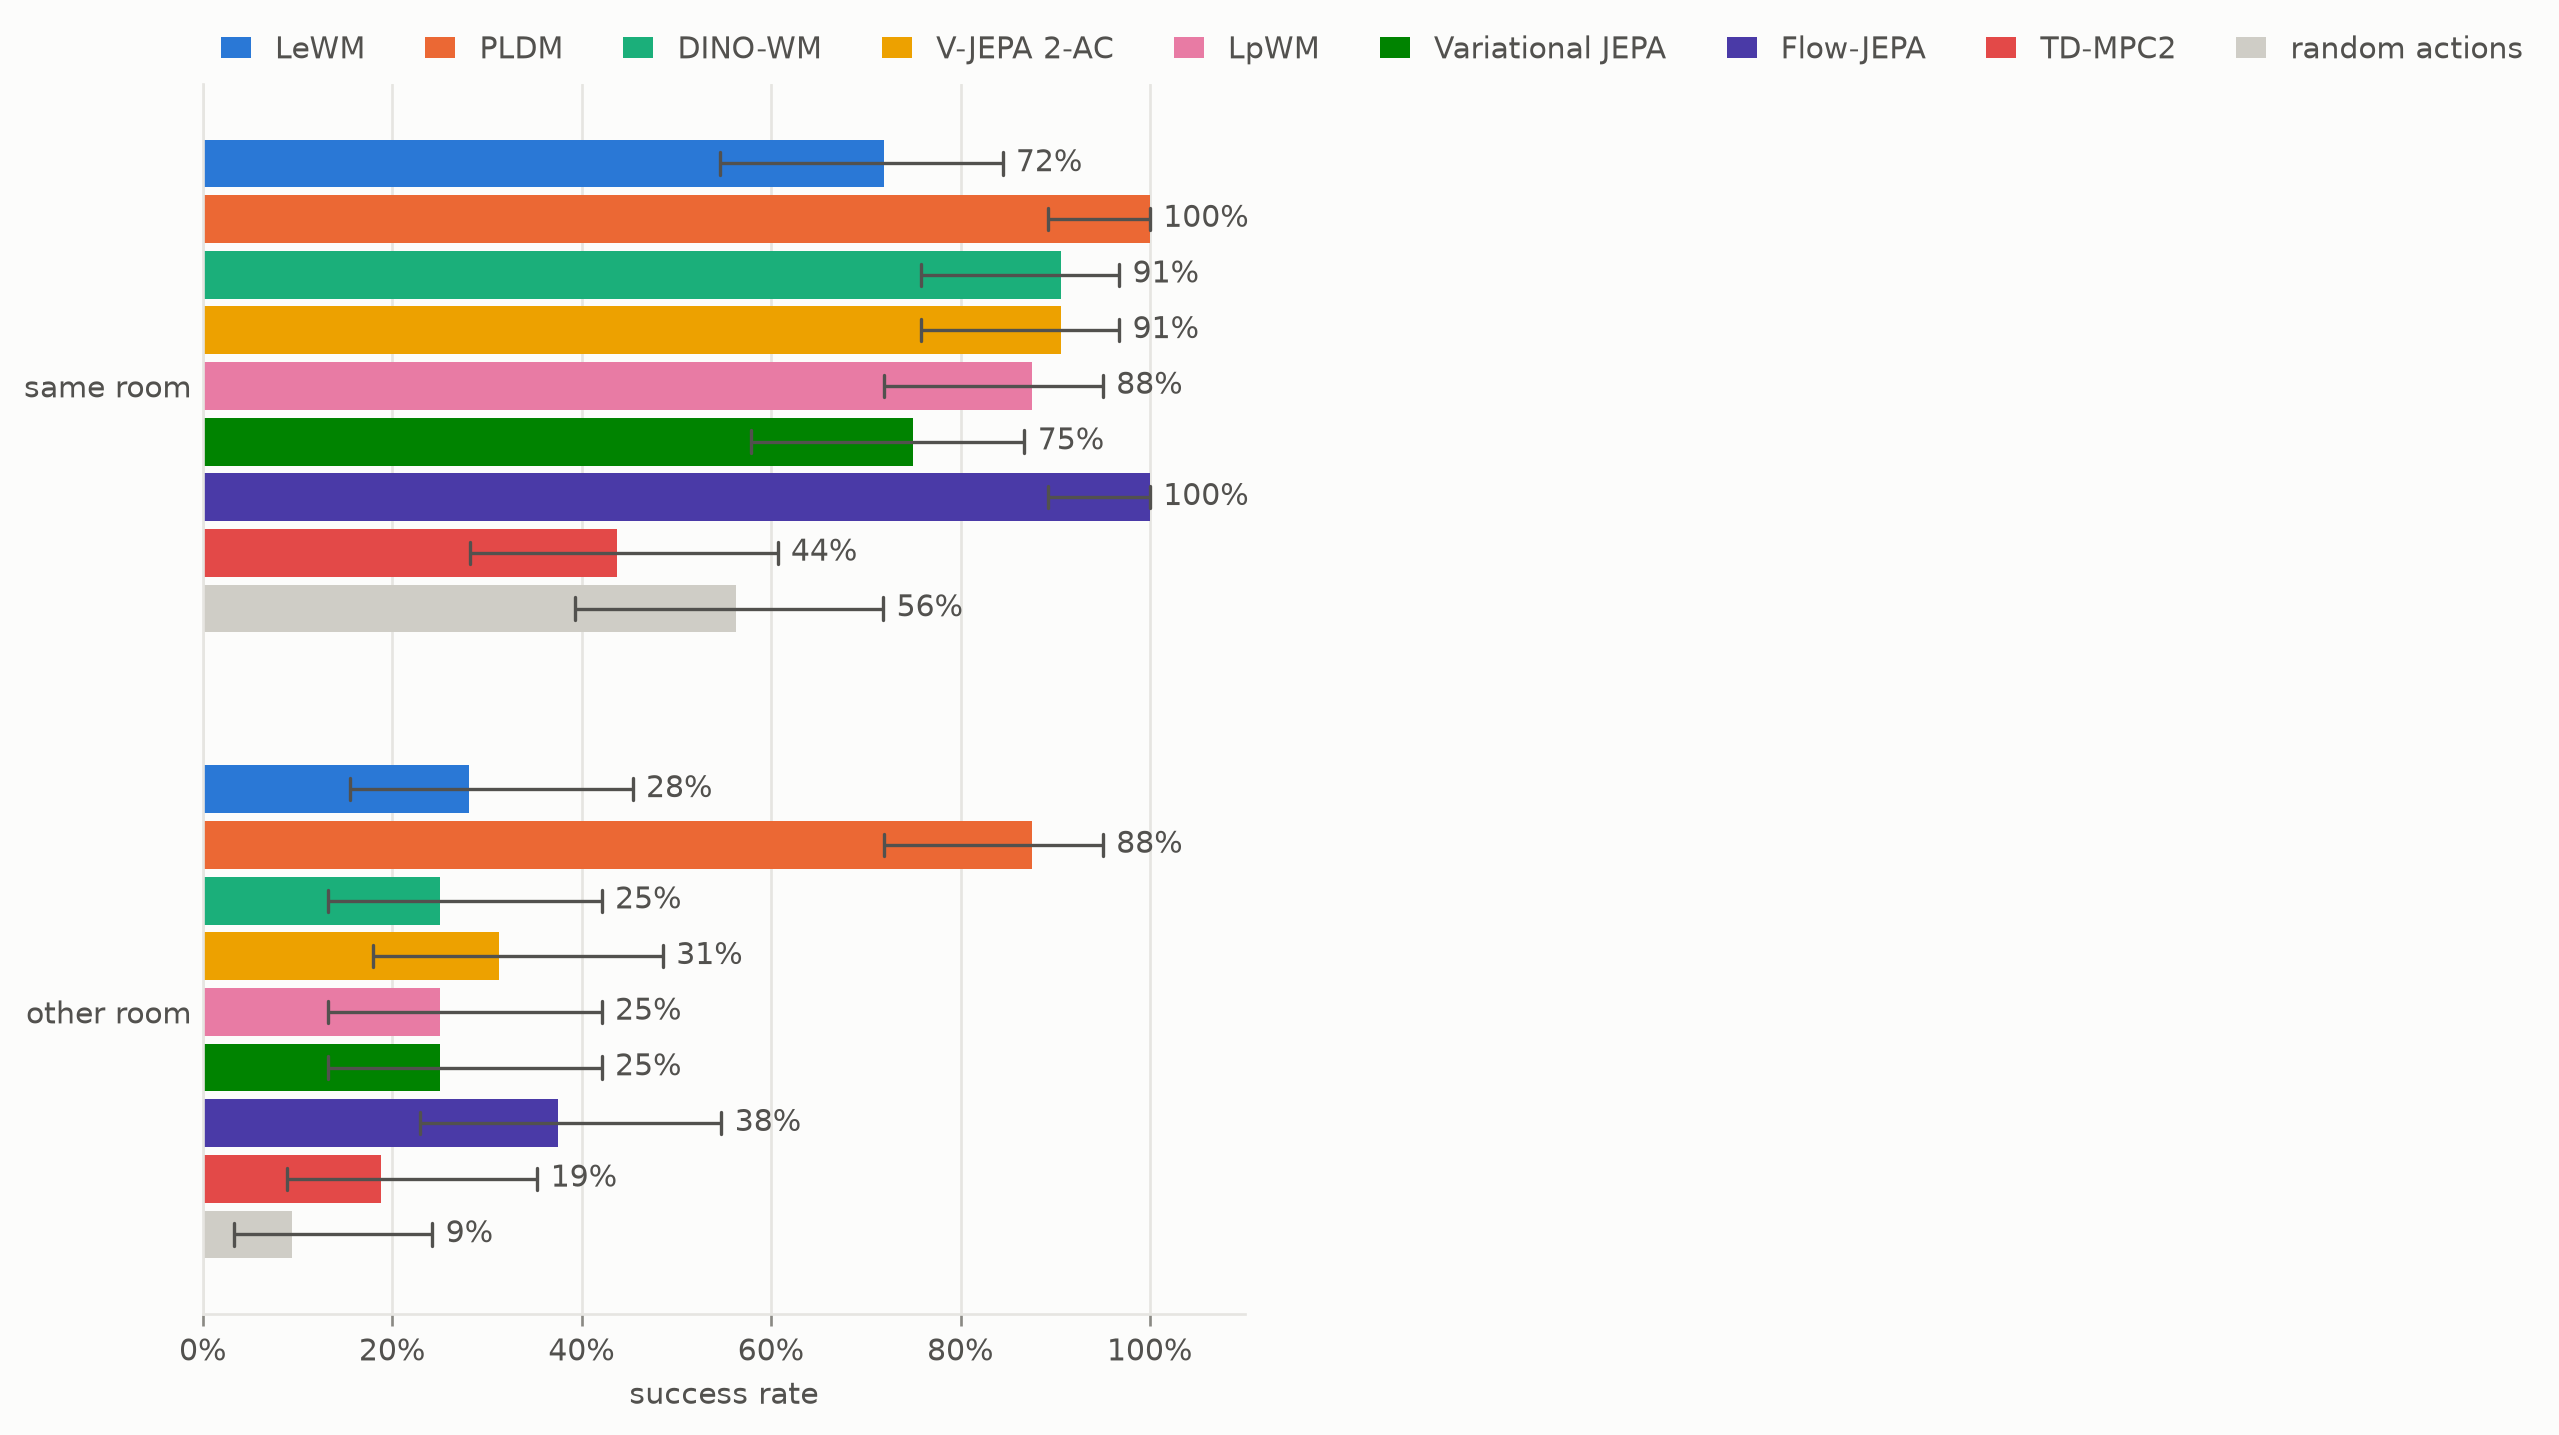

In [13]:
plots.bars({task: r.intervals() for task, r in results.items()}, xlabel="success rate", baseline="random actions")

## Does any measure predict success?
Success over all 64 tasks, against each measure. With eight models, the p-values are exact: the fraction of the 8! orderings of the models whose correlation is at least as strong. Nine measures are tested, so a p-value needs to fall below 0.05 / 9 ≈ 0.0056 to survive a Bonferroni correction. The last column correlates with success on the other-room tasks alone, the long ones that separate the models most.

In [14]:
success = {name: metrics.success_rate(torch.cat([r.success[name] for r in results.values()])) for name in models}
other_room = {name: float(results["other room"].intervals()[name]) for name in models}
names = list(models)
measures = list(table[names[0]])
orders = torch.tensor(list(itertools.permutations(range(len(names)))))


def p_values(x, y):
    # Exact two-sided permutation p-values of Spearman's ρ and Kendall's τ, over every ordering of the models.
    rx, ry = ranks(x), ranks(y)[orders]
    rx, ry = rx - rx.mean(), ry - ry.mean(1, keepdim=True)
    rho = (rx * ry).sum(1) / (rx.norm() * ry.norm(dim=1))
    x, y = torch.as_tensor(x, dtype=torch.float64), torch.as_tensor(y, dtype=torch.float64)
    sx, sy = (x[:, None] - x[None]).sign(), (y[:, None] - y[None]).sign()
    tau = (sx * sy[orders[:, :, None], orders[:, None]]).sum((1, 2)) / (sx.abs().sum() * sy.abs().sum()).sqrt()
    return [float("nan") if null[0].isnan() else (null.abs() >= null[0].abs() - 1e-9).double().mean().item() for null in (rho, tau)]


y = [float(success[n]) for n in names]
correlations, titles = {}, {}
print(f"{'':19s}{'Spearman ρ':>11s}{'p':>8s}{'Kendall τ':>11s}{'p':>8s}{'ρ, other room':>15s}")
for m in measures:
    x = [table[n][m] for n in names]
    rho, tau, (p_rho, p_tau) = spearman(x, y), kendall(x, y), p_values(x, y)
    correlations[m] = dict(rho=rho, p_rho=p_rho, tau=tau, p_tau=p_tau, rho_other=spearman(x, [other_room[n] for n in names]))
    titles[m] = f"ρ = {rho:+.2f}, τ = {tau:+.2f}"
    print(f"{m:19s}{rho:+11.2f}{p_rho:8.3f}{tau:+11.2f}{p_tau:8.3f}{correlations[m]['rho_other']:+15.2f}")

                    Spearman ρ       p  Kendall τ       p  ρ, other room
position R²              +0.63   0.100      +0.47   0.138          +0.51
room, linear             +0.17   0.691      +0.15   0.702          -0.03
room, kNN                -0.01   0.991      -0.04   0.984          -0.14


cell, attentive          -0.18   0.674      -0.25   0.467          +0.00
RankMe                   -0.17   0.694      -0.04   1.000          -0.46
LiDAR                    -0.51   0.196      -0.25   0.467          -0.71
1-step error             +0.22   0.610      +0.25   0.467          +0.07
8-step error             +0.11   0.807      +0.11   0.810          -0.07
distance fidelity        +0.75   0.038      +0.62   0.042          +0.76


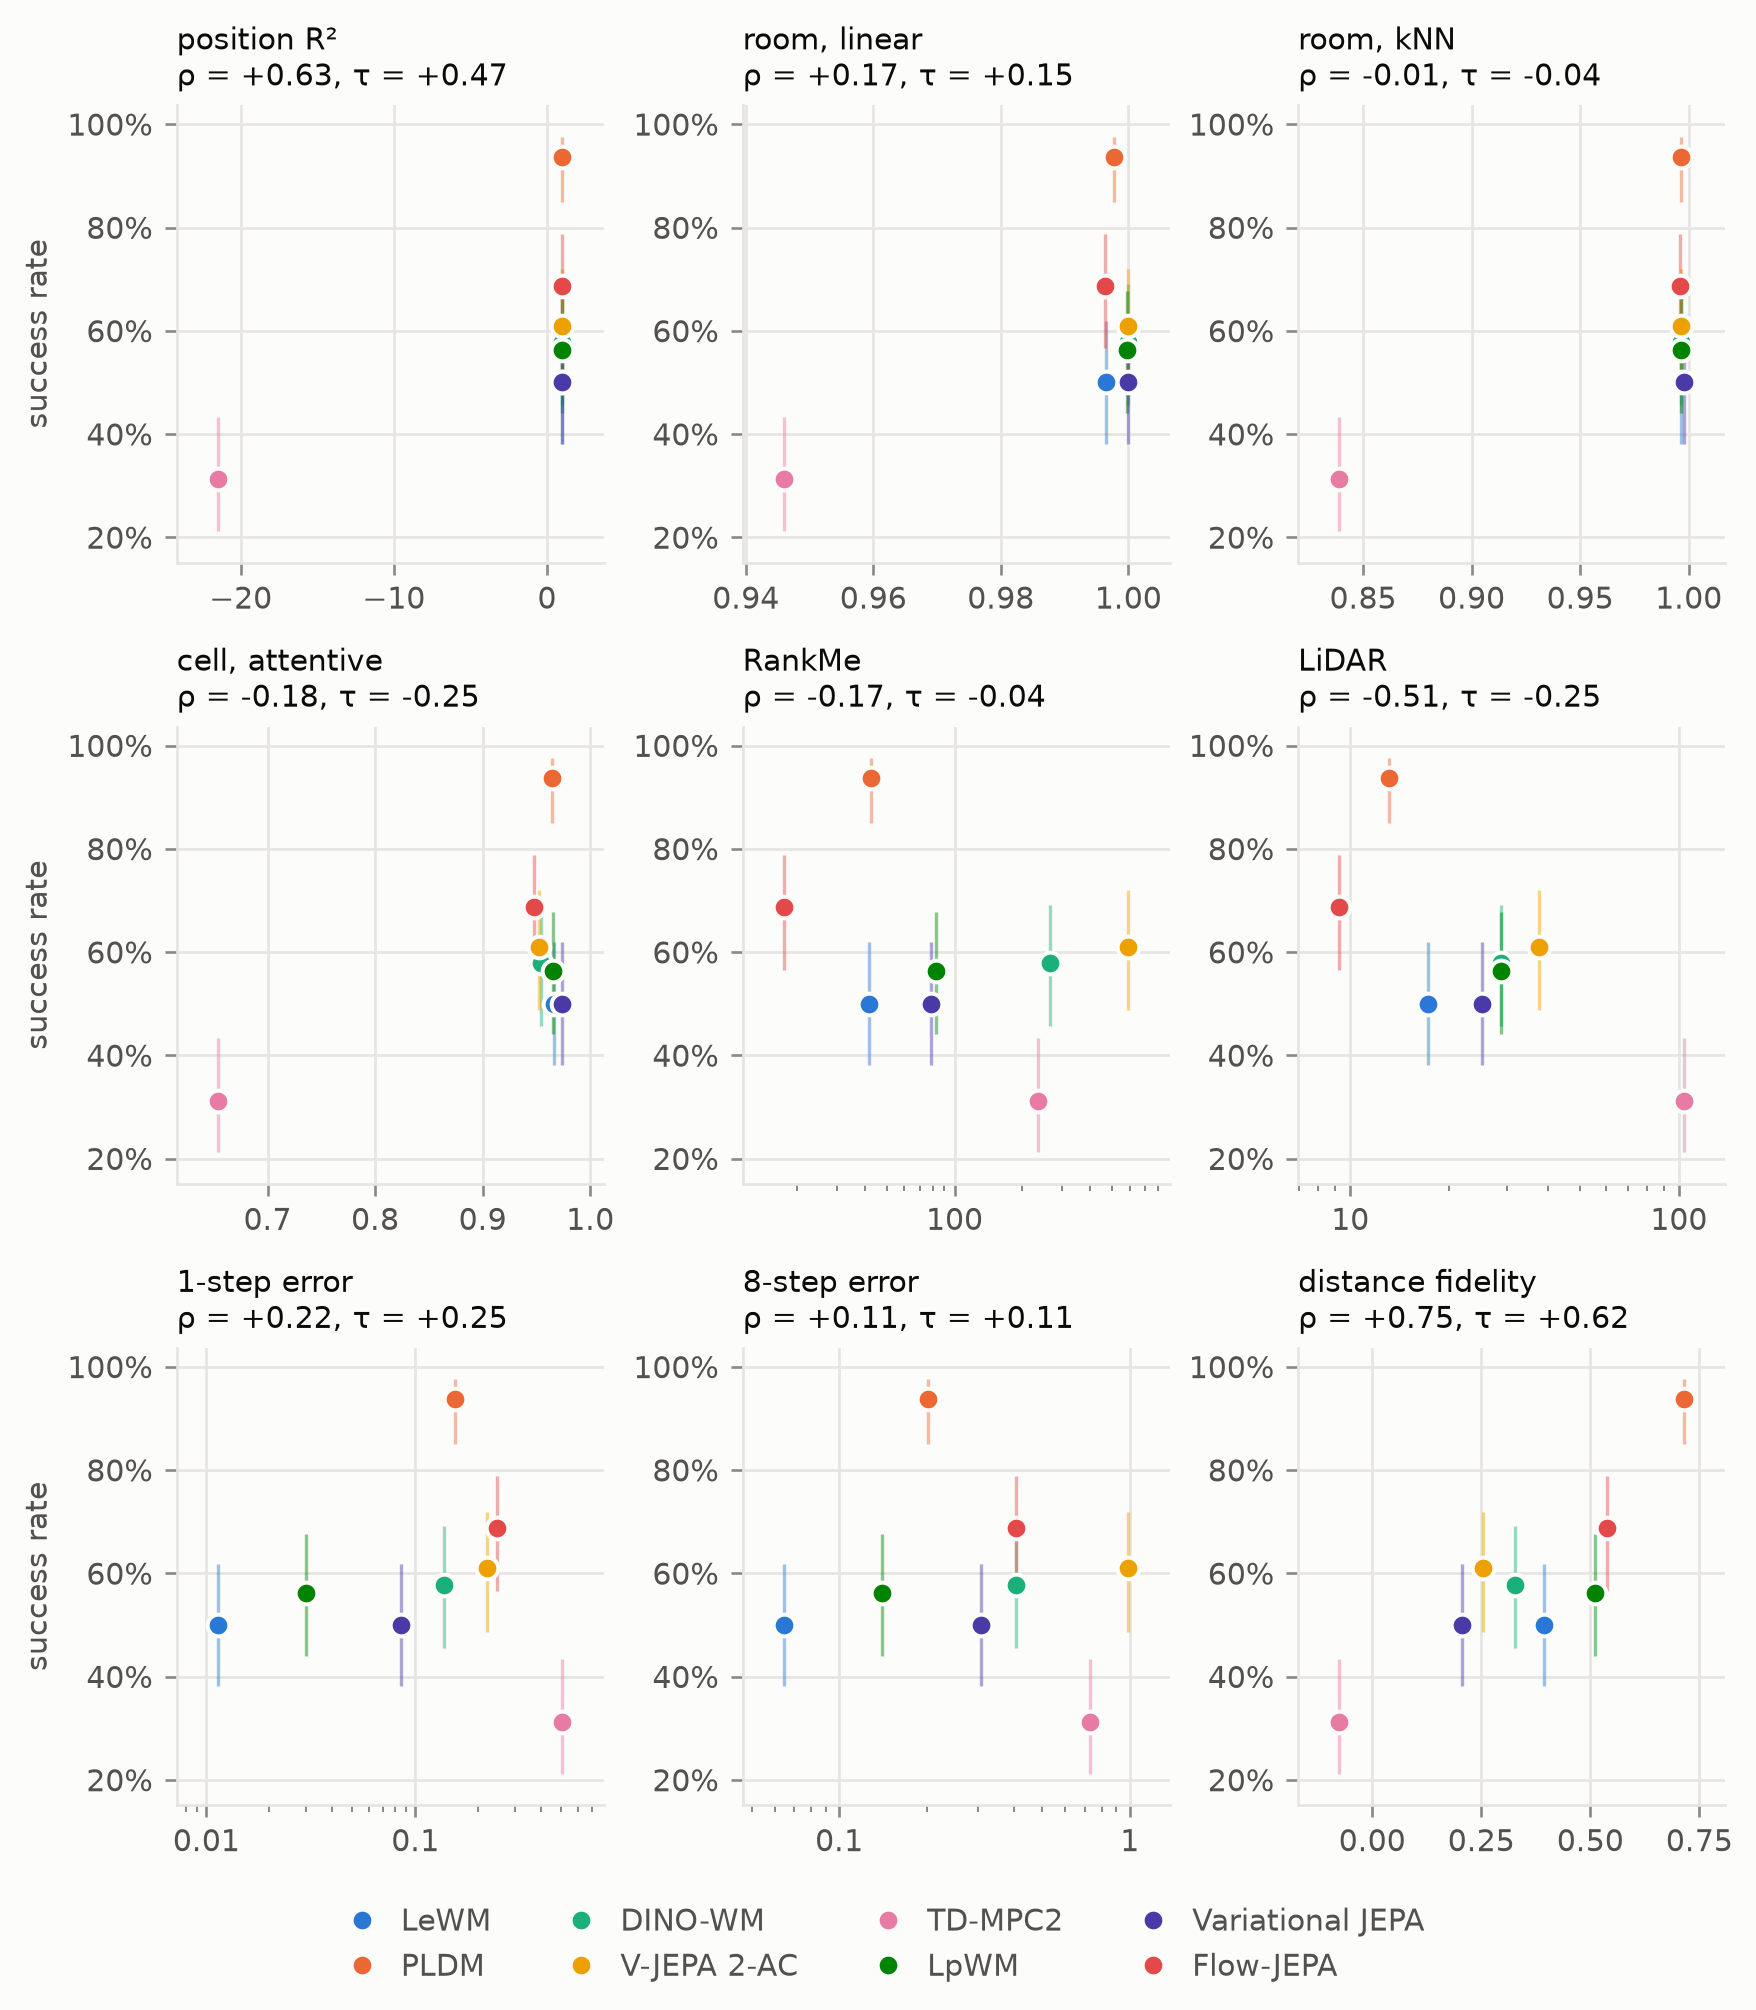

In [15]:
plots.scatter({m: {n: table[n][m] for n in names} for m in measures}, success, titles=titles, logx=("RankMe", "LiDAR", "1-step error", "8-step error"))

## Summary
**No measure predicts planning success with these eight models.** The closest is not a representation measure but a planning one: distance fidelity, how well the model's own planning cost ranks pairs of states by their geodesic distance, gives ρ = +0.75 (p = 0.038) and τ = +0.62 (p = 0.042), and +0.76 on the other-room tasks. That is suggestive, but it does not survive the correction for nine measures (0.0056), and it rests mostly on the two ends: PLDM, whose cost tracks the path through the door best (0.71), succeeds most (94%), and TD-MPC2, which plans with a value function instead of a latent distance (−0.08), succeeds least.

The generic measures say little. The probes saturate: every model except TD-MPC2 reads the position with R² ≥ 0.978, the room at 99.6% or more and the 8×8 cell at 95–97%, so they cannot separate models whose success runs from 50% to 94%. Their positive correlations come from TD-MPC2 alone, whose latent mixes in the goal image (its position R² of −21.5 is a ridge probe extrapolating from goal-dependent features, not a usable read-out). RankMe (ρ = −0.17) mostly reflects the size of the latent: the 16-token frozen encoders score 265 and 589, a 128-dimensional embedding 18–82. LiDAR is, if anything, inversely related (ρ = −0.51): Flow-JEPA and PLDM have the two lowest scores and the two highest success rates, TD-MPC2 the highest score and the lowest success. Prediction error does not rank the models either: LeWM predicts best one and eight steps ahead (normalized error 0.011 and 0.065) and plans at 50%, while PLDM's errors are ten times larger and it plans at 94%. What separates PLDM is that it learns to reach the goal through the door (88% on the other-room tasks against 25–38% for every other model), which a latent space can support only if distances in it follow the walls.

Caveats: eight points, one task and one seed per model; six of the eight success rates sit between 50% and 69% with overlapping intervals, so their order is itself uncertain; and TD-MPC2 is not a like-for-like point (another planner, a goal-conditioned latent, and a success rate that moved from 11% to 31% between two runs of this notebook). A real test of whether distance fidelity predicts planning needs many more models, for example sweeps of one method's hyperparameters, as RankMe and LiDAR were validated.

In [16]:
short = ["pos R²", "room", "room kNN", "cell att", "RankMe", "LiDAR", "err 1", "err 8", "dist ρ"]
print(f"{'':17s}{'success':>17s}{'train min':>10s}" + "".join(f"{m:>9s}" for m in short))
for name in names:
    print(f"{name:17s}{success[name]!s:>17}{minutes[name]:10.1f}" + "".join(f"{table[name][m]:9.3g}" for m in measures))

                           success train min   pos R²     room room kNN cell att   RankMe    LiDAR    err 1    err 8   dist ρ
LeWM                50% [38%, 62%]       2.6    0.998    0.997    0.996    0.966     41.6     17.3   0.0114   0.0646    0.393
PLDM                94% [85%, 98%]       8.1        1    0.998    0.996    0.965     42.8     13.1    0.156    0.202    0.714
DINO-WM             58% [46%, 69%]       2.8        1        1    0.997    0.954      265     28.8    0.137    0.406    0.327
V-JEPA 2-AC         61% [49%, 72%]      10.3        1        1    0.997    0.952      589     37.5     0.22    0.989    0.255
TD-MPC2             31% [21%, 43%]       1.0    -21.5    0.946    0.839    0.654      234      103    0.505    0.731   -0.075
LpWM                56% [44%, 68%]       2.8     0.99        1    0.997    0.965     82.4     28.7   0.0298     0.14     0.51
Variational JEPA    50% [38%, 62%]       3.1    0.978        1    0.998    0.974     78.9     25.1   0.0856    0.307  